In [1]:
import sys
print(sys.executable)

/opt/anaconda3/envs/dedalus3/bin/python


In [11]:
import os
os.environ['OMP_NUM_THREADS'] = '1'      # must be set before numpy is imported
os.environ['NUMEXPR_MAX_THREADS'] = '1'

import sys
import numpy as np
import matplotlib.pyplot as plt
import dedalus.public as d3

from mpi4py import MPI
import time

import logging
logging.disable(logging.INFO)   # hide INFO messages (Dedalus's "Building subproblem matrices..." lines)

from scipy.optimize import brentq, minimize_scalar

%matplotlib inline
print(sys.executable)

/opt/anaconda3/envs/dedalus3/bin/python


In [5]:
# CREDIT: adapted from the Dedalus examples repository (evp_1d_rayleigh_benard)

def max_growth_rate(Rayleigh, Prandtl, kx, Nz, NEV=10, target=0):
    """Largest linear growth rate, Im(omega), of no-slip Rayleigh-Benard
    convection at one horizontal wavenumber kx (nondimensionalised with
    the box height and free-fall time)."""

    # Parameters
    Lz = 1
    # Build Fourier basis for x with prescribed kx as the fundamental mode
    Nx = 2
    Lx = 2 * np.pi / kx

    # Bases
    coords = d3.CartesianCoordinates('x', 'z')
    dist = d3.Distributor(coords, dtype=np.complex128, comm=MPI.COMM_SELF)
    xbasis = d3.ComplexFourier(coords['x'], size=Nx, bounds=(0, Lx))
    zbasis = d3.ChebyshevT(coords['z'], size=Nz, bounds=(0, Lz))

    # Fields
    omega = dist.Field(name='omega')
    p = dist.Field(name='p', bases=(xbasis,zbasis))
    b = dist.Field(name='b', bases=(xbasis,zbasis))
    u = dist.VectorField(coords, name='u', bases=(xbasis,zbasis))
    tau_p = dist.Field(name='tau_p')
    tau_b1 = dist.Field(name='tau_b1', bases=xbasis)
    tau_b2 = dist.Field(name='tau_b2', bases=xbasis)
    tau_u1 = dist.VectorField(coords, name='tau_u1', bases=xbasis)
    tau_u2 = dist.VectorField(coords, name='tau_u2', bases=xbasis)

    # Substitutions
    kappa = (Rayleigh * Prandtl)**(-1/2)
    nu = (Rayleigh / Prandtl)**(-1/2)
    x, z = dist.local_grids(xbasis, zbasis)
    ex, ez = coords.unit_vector_fields(dist)
    lift_basis = zbasis.derivative_basis(1)
    lift = lambda A: d3.Lift(A, lift_basis, -1)
    grad_u = d3.grad(u) + ez*lift(tau_u1) # First-order reduction
    grad_b = d3.grad(b) + ez*lift(tau_b1) # First-order reduction
    dt = lambda A: -1j*omega*A

    # Problem
    problem = d3.EVP([p, b, u, tau_p, tau_b1, tau_b2, tau_u1, tau_u2], namespace=locals(), eigenvalue=omega)
    problem.add_equation("trace(grad_u) + tau_p = 0")
    problem.add_equation("dt(b) - kappa*div(grad_b) + lift(tau_b2) - ez@u = 0")
    problem.add_equation("dt(u) - nu*div(grad_u) + grad(p) - b*ez + lift(tau_u2) = 0")
    problem.add_equation("b(z=0) = 0")
    problem.add_equation("u(z=0) = 0")
    problem.add_equation("b(z=Lz) = 0")
    problem.add_equation("u(z=Lz) = 0")
    problem.add_equation("integ(p) = 0") # Pressure gauge

    # Solver
    solver = problem.build_solver(entry_cutoff=0)
    solver.solve_sparse(solver.subproblems[1], NEV, target=target)
    return np.max(solver.eigenvalues.imag)


def growth_over_kx_range(Rayleigh, Prandtl, kx_values, Nz, NEV=10, target=0):
    """Largest growth rate at each wavenumber in kx_values, for one Rayleigh
    number. Returns an array the same length as kx_values."""
    return np.array([max_growth_rate(Rayleigh, Prandtl, kx, Nz, NEV=NEV, target=target)
                     for kx in kx_values])

Solve time: 6.2 s
Max growth rate = 4.119e-04 at kx = 3.1173


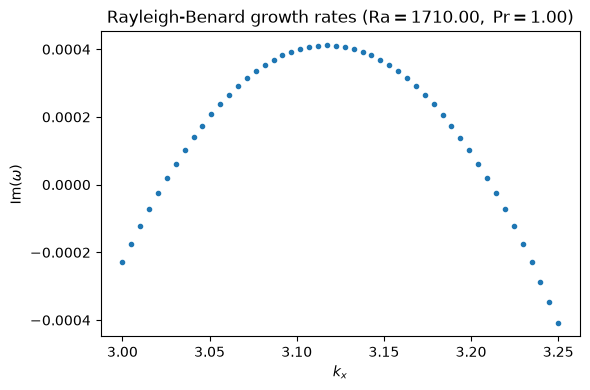

In [10]:
Ra = 1710
Prandtl = 1
Nz = 64
kx_values = np.linspace(3.0, 3.25, 50)

t0 = time.time()
growth = growth_over_kx_range(Ra, Prandtl, kx_values, Nz)
print(f'Solve time: {time.time() - t0:.1f} s')
print(f'Max growth rate = {growth.max():.3e} at kx = {kx_values[growth.argmax()]:.4f}')

plt.figure(figsize=(6, 4))
plt.plot(kx_values, growth, '.')
plt.xlabel(r'$k_x$')
plt.ylabel(r'$\mathrm{Im}(\omega)$')
plt.title(r'Rayleigh-Benard growth rates ($\mathrm{Ra} = %.2f, \; \mathrm{Pr} = %.2f$)' % (Ra, Prandtl))
plt.tight_layout()
plt.savefig('growth_rates_vs_kx.pdf')
plt.show()

In [14]:
def peak_growth(Rayleigh, Prandtl, kx_bounds, Nz, NEV=10, kx_tol=1e-3):
    """Maximise the growth rate over kx (continuously, not just on a grid).
    Returns (max growth rate, kx at the maximum).""" 
    res = minimize_scalar(lambda kx: -max_growth_rate(Rayleigh, Prandtl, kx, Nz, NEV=NEV),
                          bounds=kx_bounds, method='bounded', options={'xatol': kx_tol})
    return -res.fun, res.x

In [15]:
Prandtl = 1
Nz = 64
NEV = 10
kx_range = np.linspace(2.0, 4.5, 30)
Ra_range = np.linspace(1000, 2500, 16)

t0 = time.time()
growth_2d = np.zeros((len(Ra_range), len(kx_range)))
for i, Ra in enumerate(Ra_range):
    growth_2d[i, :] = growth_over_kx_range(Ra, Prandtl, kx_range, Nz, NEV=NEV)
    print(f'Finished Ra = {Ra:.1f} ({i+1}/{len(Ra_range)})')
print(f'Scan took {time.time() - t0:.0f} s')
np.savez('growth_2d.npz', Ra_range=Ra_range, kx_range=kx_range, growth_2d=growth_2d)

# To reload later without rerunning the scan, use:
# data = np.load('growth_2d.npz')
# Ra_range, kx_range, growth_2d = data['Ra_range'], data['kx_range'], data['growth_2d']

Finished Ra = 1000.0 (1/16)
Finished Ra = 1100.0 (2/16)
Finished Ra = 1200.0 (3/16)
Finished Ra = 1300.0 (4/16)
Finished Ra = 1400.0 (5/16)
Finished Ra = 1500.0 (6/16)
Finished Ra = 1600.0 (7/16)
Finished Ra = 1700.0 (8/16)
Finished Ra = 1800.0 (9/16)
Finished Ra = 1900.0 (10/16)
Finished Ra = 2000.0 (11/16)
Finished Ra = 2100.0 (12/16)
Finished Ra = 2200.0 (13/16)
Finished Ra = 2300.0 (14/16)
Finished Ra = 2400.0 (15/16)
Finished Ra = 2500.0 (16/16)
Scan took 65 s


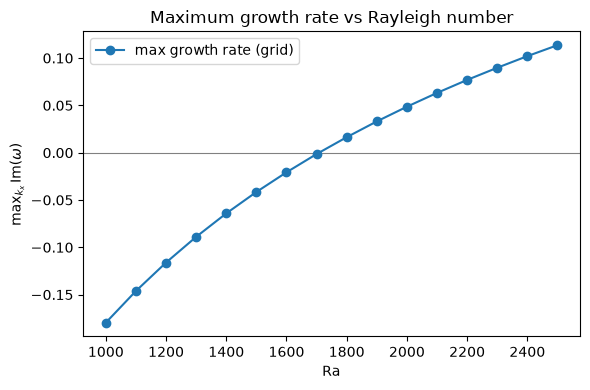

In [16]:
max_growth_vs_Ra = growth_2d.max(axis=1)

plt.figure(figsize=(6, 4))
plt.axhline(0, color='gray', lw=0.8)
plt.plot(Ra_range, max_growth_vs_Ra, 'o-', label='max growth rate (grid)')
plt.xlabel(r'$\mathrm{Ra}$')
plt.ylabel(r'max$_{k_x}\,\mathrm{Im}(\omega)$')
plt.title('Maximum growth rate vs Rayleigh number')
plt.legend()
plt.tight_layout()
plt.savefig('max_growth_vs_Ra_grid.pdf')
plt.show()

In [17]:
# Bracket the root: first pair of neighbouring Ra values where the max growth rate changes sign
sign_changes = np.where(np.diff(np.sign(max_growth_vs_Ra)))[0]
if len(sign_changes) == 0:
    raise ValueError('No sign change in max growth rate: widen Ra_range.')
i0 = sign_changes[0]
Ra_bracket = (Ra_range[i0], Ra_range[i0 + 1])
kx_bounds = (kx_range[0], kx_range[-1])
Ra_tol = 1e-2
kx_tol = 1e-3

# Refine with Brent's method, optimising over kx at each trial Ra
Ra_crit = brentq(lambda Ra: peak_growth(Ra, Prandtl, kx_bounds, Nz, NEV, kx_tol)[0],
                 *Ra_bracket, xtol=Ra_tol)
kx_crit = peak_growth(Ra_crit, Prandtl, kx_bounds, Nz, NEV, kx_tol)[1]

print(f'Numerical Ra_c = {Ra_crit:.4f}, kx_c = {kx_crit:.4f}')
print('Analytical:      Ra_c = 1707.76, kx_c = 3.117')

Numerical Ra_c = 1707.7625, kx_c = 3.1164
Analytical:      Ra_c = 1707.76, kx_c = 3.117


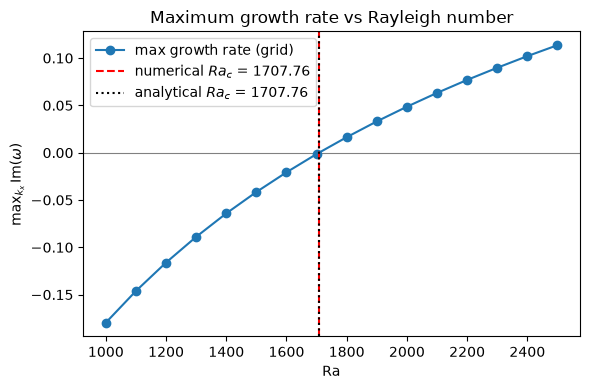

In [18]:
plt.figure(figsize=(6, 4))
plt.axhline(0, color='gray', lw=0.8)
plt.plot(Ra_range, max_growth_vs_Ra, 'o-', label='max growth rate (grid)')
plt.axvline(Ra_crit, color='red', ls='--', label=r'numerical $Ra_c$ = %.2f' % Ra_crit)
plt.axvline(1707.76, color='black', ls=':', label=r'analytical $Ra_c$ = 1707.76')
plt.xlabel(r'$\mathrm{Ra}$')
plt.ylabel(r'max$_{k_x}\,\mathrm{Im}(\omega)$')
plt.title('Maximum growth rate vs Rayleigh number')
plt.legend()
plt.tight_layout()
plt.savefig('max_growth_vs_Ra.pdf')
plt.show()

8 neutral-curve points found


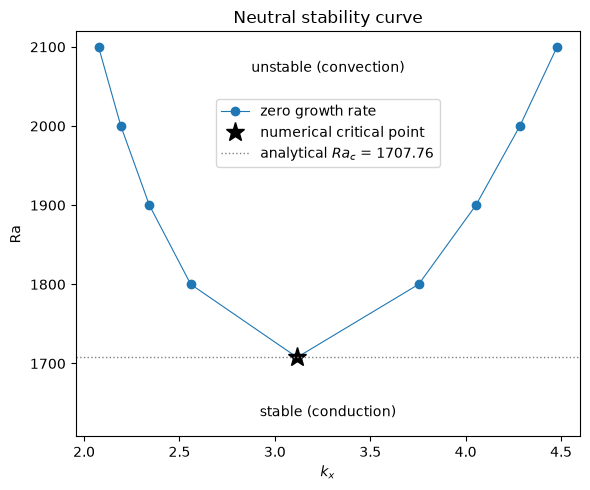

In [22]:
# Zero crossings along kx for each Ra, by linear interpolation between grid points
kx_pts, Ra_pts = [], []
for Ra, row in zip(Ra_range, growth_2d):
    s = np.sign(row)
    for i in np.where(s[:-1] * s[1:] < 0)[0]:    # sign change between grid points i and i+1
        kx_cross = kx_range[i] - row[i] * (kx_range[i+1] - kx_range[i]) / (row[i+1] - row[i])
        kx_pts.append(kx_cross)
        Ra_pts.append(Ra)
print(f'{len(kx_pts)} neutral-curve points found')

# Add the critical point as the bottom of the curve, then sort by kx
kx_all = np.append(kx_pts, kx_crit)
Ra_all = np.append(Ra_pts, Ra_crit)
order = np.argsort(kx_all)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(kx_all[order], Ra_all[order], 'o-', lw=0.8, label='zero growth rate')
ax.plot(kx_crit, Ra_crit, 'k*', markersize=14, label='numerical critical point')
ax.axhline(1707.76, color='gray', ls=':', lw=1, label=r'analytical $Ra_c$ = 1707.76')
ax.text(0.5, 0.9, 'unstable (convection)', transform=ax.transAxes, ha='center')
ax.text(0.5, 0.05, 'stable (conduction)', transform=ax.transAxes, ha='center')
ax.set_ylim(bottom=Ra_crit - 100)
ax.set_xlabel(r'$k_x$')
ax.set_ylabel(r'$\mathrm{Ra}$')
ax.set_title('Neutral stability curve')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 0.85))
fig.tight_layout()
fig.savefig('neutral_curve.pdf')
plt.show()

In [23]:
import os, shutil, pathlib
import h5py

In [24]:
# CREDIT: adapted from the Dedalus examples repository (ivp_2d_rayleigh_benard)

def run_rayleigh_benard(Rayleigh, stop_sim_time, Nx=256, Nz=64, Prandtl=1, Lx=4, Lz=1,
                        outdir=None, overwrite=False, snapshot_dt=0.25, max_timestep=0.125):
    """Run 2D horizontally periodic Rayleigh-Benard convection (no-slip, fixed
    temperature) and save buoyancy snapshots to a folder of HDF5 files.

    Nondimensionalised with the box height and free-fall time:
        kappa = (Rayleigh*Prandtl)**(-1/2),  nu = (Rayleigh/Prandtl)**(-1/2).
    The folder is named after Ra (e.g. snapshots_Ra2e06) unless outdir is given.
    If the folder already exists the run is skipped, unless overwrite=True.
    Returns the folder name."""

    if outdir is None:
        outdir = f'snapshots_Ra{Rayleigh:.0e}'.replace('+', '')
    if os.path.exists(outdir):
        if overwrite:
            shutil.rmtree(outdir)
        else:
            print(f'{outdir} already exists: skipping (use overwrite=True to rerun)')
            return outdir

    dealias = 3/2
    timestepper = d3.RK222
    dtype = np.float64

    # Bases
    coords = d3.CartesianCoordinates('x', 'z')
    dist = d3.Distributor(coords, dtype=dtype)
    xbasis = d3.RealFourier(coords['x'], size=Nx, bounds=(0, Lx), dealias=dealias)
    zbasis = d3.ChebyshevT(coords['z'], size=Nz, bounds=(0, Lz), dealias=dealias)

    # Fields
    p = dist.Field(name='p', bases=(xbasis,zbasis))
    b = dist.Field(name='b', bases=(xbasis,zbasis))
    u = dist.VectorField(coords, name='u', bases=(xbasis,zbasis))
    tau_p = dist.Field(name='tau_p')
    tau_b1 = dist.Field(name='tau_b1', bases=xbasis)
    tau_b2 = dist.Field(name='tau_b2', bases=xbasis)
    tau_u1 = dist.VectorField(coords, name='tau_u1', bases=xbasis)
    tau_u2 = dist.VectorField(coords, name='tau_u2', bases=xbasis)

    # Substitutions
    kappa = (Rayleigh * Prandtl)**(-1/2)
    nu = (Rayleigh / Prandtl)**(-1/2)
    x, z = dist.local_grids(xbasis, zbasis)
    ex, ez = coords.unit_vector_fields(dist)
    lift_basis = zbasis.derivative_basis(1)
    lift = lambda A: d3.Lift(A, lift_basis, -1)
    grad_u = d3.grad(u) + ez*lift(tau_u1) # First-order reduction
    grad_b = d3.grad(b) + ez*lift(tau_b1) # First-order reduction

    # Problem
    problem = d3.IVP([p, b, u, tau_p, tau_b1, tau_b2, tau_u1, tau_u2], namespace=locals())
    problem.add_equation("trace(grad_u) + tau_p = 0")
    problem.add_equation("dt(b) - kappa*div(grad_b) + lift(tau_b2) = - u@grad(b)")
    problem.add_equation("dt(u) - nu*div(grad_u) + grad(p) - b*ez + lift(tau_u2) = - u@grad(u)")
    problem.add_equation("b(z=0) = Lz")
    problem.add_equation("u(z=0) = 0")
    problem.add_equation("b(z=Lz) = 0")
    problem.add_equation("u(z=Lz) = 0")
    problem.add_equation("integ(p) = 0") # Pressure gauge

    # Solver
    solver = problem.build_solver(timestepper)
    solver.stop_sim_time = stop_sim_time

    # Initial conditions
    b.fill_random('g', seed=42, distribution='normal', scale=1e-3) # Random noise
    b['g'] *= z * (Lz - z) # Damp noise at walls
    b['g'] += Lz - z # Add linear background

    # Analysis: buoyancy only
    snapshots = solver.evaluator.add_file_handler(outdir, sim_dt=snapshot_dt, max_writes=50)
    snapshots.add_task(b, name='buoyancy')

    # CFL
    CFL = d3.CFL(solver, initial_dt=max_timestep, cadence=10, safety=0.5, threshold=0.05,
                 max_change=1.5, min_change=0.5, max_dt=max_timestep)
    CFL.add_velocity(u)

    # Main loop
    t0 = time.time()
    while solver.proceed:
        timestep = CFL.compute_timestep()
        solver.step(timestep)
        if solver.iteration % 200 == 0:
            print(f'  Ra = {Rayleigh:.0e}:  t = {solver.sim_time:.1f} / {stop_sim_time},  dt = {timestep:.4f}')
    print(f'Ra = {Rayleigh:.0e} finished in {time.time() - t0:.0f} s -> {outdir}')
    return outdir

In [71]:
def load_task(folder, task='buoyancy'):
    """Read one saved task from every .h5 file in folder.
    Returns times, x, z, data, with data of shape (n_times, Nx, Nz), sorted by time."""
    times, chunks = [], []
    x = z = None
    for fname in sorted(pathlib.Path(folder).glob('*.h5')):
        with h5py.File(fname, mode='r') as f:
            dset = f['tasks'][task]
            if x is None:
                x = dset.dims[1][0][:]
                z = dset.dims[2][0][:]
            times.append(f['scales/sim_time'][:])
            chunks.append(dset[:])
    times = np.concatenate(times)
    data = np.concatenate(chunks)
    order = np.argsort(times)
    return times[order], x, z, data[order]

In [25]:
outdir = run_rayleigh_benard(2e6, stop_sim_time=50)

snapshots_Ra2e06 already exists: skipping (use overwrite=True to rerun)


200 snapshots, t = 0.00 to 49.75


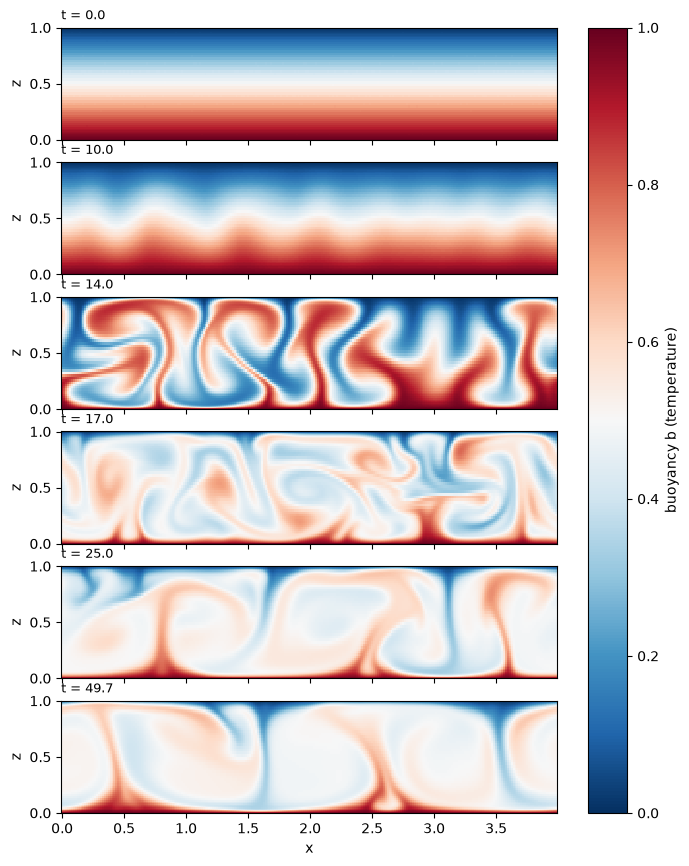

In [26]:
times, x, z, b = load_task(outdir, 'buoyancy')
print(f'{len(times)} snapshots, t = {times[0]:.2f} to {times[-1]:.2f}')

times_to_show = [0, 10, 14, 17, 25, 50]    # edit freely: each gives one panel
fig, axes = plt.subplots(len(times_to_show), 1, figsize=(8, 1.7*len(times_to_show)), sharex=True)
for ax, t_show in zip(axes, times_to_show):
    i = np.argmin(np.abs(times - t_show))      # snapshot nearest to the requested time
    im = ax.pcolormesh(x, z, b[i].T, cmap='RdBu_r', vmin=0, vmax=1, shading='nearest')
    ax.set_title(f't = {times[i]:.1f}', fontsize=9, loc='left')
    ax.set_ylabel('z')
axes[-1].set_xlabel('x')
fig.colorbar(im, ax=axes, label='buoyancy b (temperature)')
fig.savefig('snapshots.png', dpi=150, bbox_inches='tight')
plt.show()

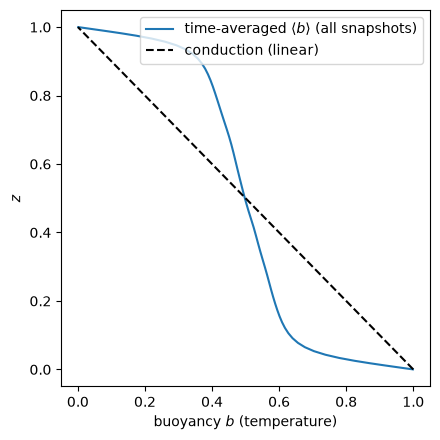

In [28]:
Lz = 1
bxm = b.mean(axis=1)                  # x-average of every snapshot -> (n_times, Nz)
b_mean_all = bxm.mean(axis=0)         # average over every snapshot, including the start-up

plt.figure(figsize=(4.5, 4.5))
plt.plot(b_mean_all, z, label=r'time-averaged $\langle b\rangle$ (all snapshots)')
plt.plot(Lz - z, z, 'k--', label='conduction (linear)')
plt.xlabel('buoyancy $b$ (temperature)')
plt.ylabel('$z$')
plt.legend()
plt.tight_layout()
plt.savefig('mean_profile_all_Ra2e06.pdf')
plt.show()

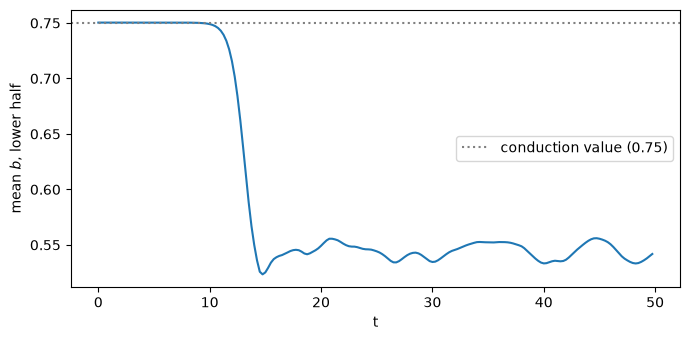

In [29]:
#Find out where convection kicks in, so I can discard the conduction-like results before that
w = np.gradient(z)                    # approximate layer thickness at each z point
low = z < 0.5
b_low = (bxm[:, low] * w[low]).sum(axis=1) / w[low].sum()

plt.figure(figsize=(7, 3.5))
plt.plot(times, b_low)
plt.axhline(0.75, color='gray', ls=':', label='conduction value (0.75)')
plt.xlabel('t')
plt.ylabel('mean $b$, lower half')
plt.legend()
plt.tight_layout()
plt.savefig('lower_half_mean_Ra2e06.pdf')
plt.show()

139 of 200 snapshots used, t = 15.25 to 49.75
Max deviation from conduction:  all snapshots 0.269,  after t = 15 0.360


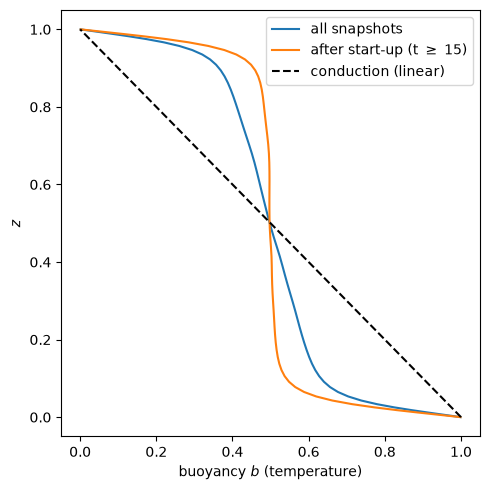

In [30]:
tstart = 15    # rom the plot above, this is where the dip has levelled off

keep = times >= tstart
b_mean_steady = bxm[keep].mean(axis=0)
print(f'{keep.sum()} of {len(times)} snapshots used, t = {times[keep][0]:.2f} to {times[keep][-1]:.2f}')
print(f'Max deviation from conduction:  all snapshots {np.abs(b_mean_all - (Lz - z)).max():.3f},  '
      f'after t = {tstart} {np.abs(b_mean_steady - (Lz - z)).max():.3f}')

plt.figure(figsize=(5, 5))
plt.plot(b_mean_all, z, label='all snapshots')
plt.plot(b_mean_steady, z, label=f'after start-up (t $\\geq$ {tstart})')
plt.plot(Lz - z, z, 'k--', label='conduction (linear)')
plt.xlabel('buoyancy $b$ (temperature)')
plt.ylabel('$z$')
plt.legend()
plt.tight_layout()
plt.savefig('mean_profile_comparison_Ra2e06.pdf')
plt.show()

In [ ]:
#Now need to loop over lots of Ra and extract the temp profiles from them. 
#Will choose 1e4, 1e and 1e6.

In [47]:
# Rayleigh numbers and how long to run each: the stop times are guesses, will check them in the settling plot
runs = {2e3:200, 1e4: 100, 1e5: 75, 2e6: 50}

folders = {}
for Ra, t_stop in runs.items():
    folders[Ra] = run_rayleigh_benard(Ra, stop_sim_time=t_stop)

  Ra = 2e+03:  t = 25.0 / 200,  dt = 0.1250
  Ra = 2e+03:  t = 50.0 / 200,  dt = 0.1250
  Ra = 2e+03:  t = 75.0 / 200,  dt = 0.1250
  Ra = 2e+03:  t = 100.0 / 200,  dt = 0.1250
  Ra = 2e+03:  t = 125.0 / 200,  dt = 0.1250
  Ra = 2e+03:  t = 150.0 / 200,  dt = 0.1250
  Ra = 2e+03:  t = 175.0 / 200,  dt = 0.1250
  Ra = 2e+03:  t = 200.0 / 200,  dt = 0.1250
Ra = 2e+03 finished in 88 s -> snapshots_Ra2e03
  Ra = 1e+04:  t = 25.0 / 100,  dt = 0.1250
  Ra = 1e+04:  t = 33.3 / 100,  dt = 0.0234
  Ra = 1e+04:  t = 38.6 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 44.2 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 49.8 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 55.3 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 60.9 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 66.5 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 72.1 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 77.7 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 83.3 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 88.9 / 100,  dt = 0.0279
  Ra = 1e+04:  t = 94.4 / 100,  dt = 0.0279
Ra = 1e+04 finished in 

In [48]:
#load all the runs and x-average them
Lz = 1
data = {}
for Ra, folder in folders.items():
    t, x, z, b = load_task(folder, 'buoyancy')
    data[Ra] = dict(t=t, z=z, bxm=b.mean(axis=1))      # bxm: x-average, shape (n_times, Nz)
    print(f'Ra = {Ra:.0e}: {len(t)} snapshots, t = {t[0]:.1f} to {t[-1]:.1f}')

Ra = 2e+03: 800 snapshots, t = 0.0 to 199.8
Ra = 1e+04: 401 snapshots, t = 0.0 to 100.0
Ra = 1e+05: 301 snapshots, t = 0.0 to 75.0
Ra = 2e+06: 200 snapshots, t = 0.0 to 49.7


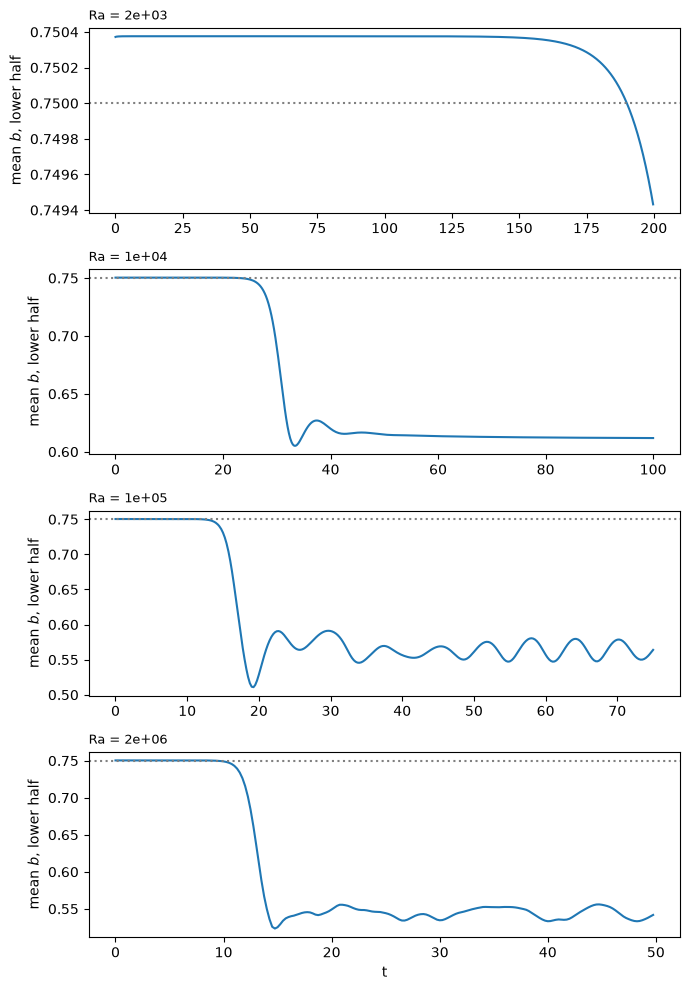

In [49]:
#settling check for every run (one panel each)
fig, axes = plt.subplots(len(data), 1, figsize=(7, 2.5*len(data)))
for ax, (Ra, d) in zip(axes, data.items()):
    w = np.gradient(d['z'])
    low = d['z'] < 0.5
    b_low = (d['bxm'][:, low] * w[low]).sum(axis=1) / w[low].sum()
    ax.plot(d['t'], b_low)
    ax.axhline(0.75, color='gray', ls=':')
    ax.set_title(f'Ra = {Ra:.0e}', loc='left', fontsize=9)
    ax.set_ylabel('mean $b$, lower half')
axes[-1].set_xlabel('t')
fig.tight_layout()
plt.show()

In [ ]:
#convection barely took hold in the 2e3 place. I will delete this run and redo at 5e3:

In [51]:
del folders[2e3]
print(folders)

{10000.0: 'snapshots_Ra1e04', 100000.0: 'snapshots_Ra1e05', 2000000.0: 'snapshots_Ra2e06'}


In [62]:
#and need to delete the data entries:
data.pop(2e3, None)       # remove Ra = 2000 from the loaded data (does nothing if it's already gone)

In [52]:
folders[5e3] = run_rayleigh_benard(5e3, stop_sim_time=200)

  Ra = 5e+03:  t = 25.0 / 200,  dt = 0.1250
  Ra = 5e+03:  t = 44.4 / 200,  dt = 0.0364
  Ra = 5e+03:  t = 50.3 / 200,  dt = 0.0282
  Ra = 5e+03:  t = 56.0 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 61.9 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 67.8 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 73.8 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 79.7 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 85.6 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 91.5 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 97.4 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 103.3 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 109.3 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 115.2 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 121.1 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 127.0 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 132.9 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 138.8 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 144.8 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 150.7 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 156.6 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 162.5 / 200,  dt = 0.0296
  Ra = 5e+03:  t = 16

Ra = 5e+03: 801 snapshots, t = 0.0 to 200.0


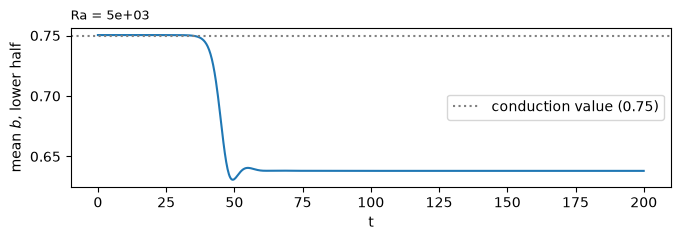

In [53]:
#now plot the settling plot for just 5e3 to see when convection settled: 
Ra_new = 5e3
t_new, x_new, z_new, b_new = load_task(folders[Ra_new], 'buoyancy')
data[Ra_new] = dict(t=t_new, z=z_new, bxm=b_new.mean(axis=1))
print(f'Ra = {Ra_new:.0e}: {len(t_new)} snapshots, t = {t_new[0]:.1f} to {t_new[-1]:.1f}')

d = data[Ra_new]
w = np.gradient(d['z'])
low = d['z'] < 0.5
b_low = (d['bxm'][:, low] * w[low]).sum(axis=1) / w[low].sum()

plt.figure(figsize=(7, 2.5))
plt.plot(d['t'], b_low)
plt.axhline(0.75, color='gray', ls=':', label='conduction value (0.75)')
plt.title(f'Ra = {Ra_new:.0e}', loc='left', fontsize=9)
plt.xlabel('t')
plt.ylabel('mean $b$, lower half')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#definitely settled in time (by around 60), so can use this

In [54]:
#check folder contents:
print(folders)

{10000.0: 'snapshots_Ra1e04', 100000.0: 'snapshots_Ra1e05', 2000000.0: 'snapshots_Ra2e06', 5000.0: 'snapshots_Ra5e03'}


Ra = 5e+03: 561 snapshots used (t >= 60)
Ra = 1e+04: 241 snapshots used (t >= 40)
Ra = 1e+05: 201 snapshots used (t >= 25)
Ra = 2e+06: 139 snapshots used (t >= 15)


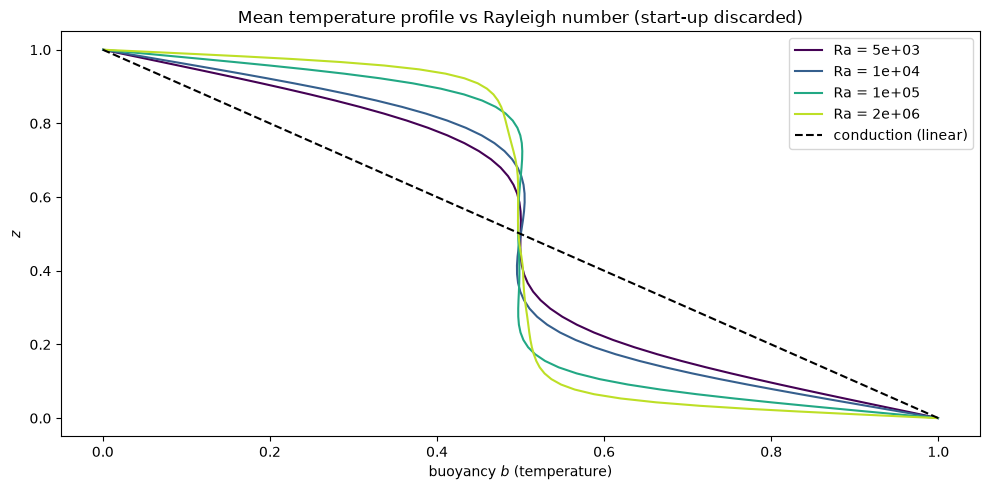

In [58]:
# Setting each start-up cutoff, using the panels above, after the dip has levelled off.
tstart = {5e3:60, 1e4: 40, 1e5: 25, 2e6: 15}

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(data)))
for (Ra, d), color in zip(sorted(data.items()), colors):
    keep = d['t'] >= tstart[Ra]
    if keep.sum() == 0:
        raise ValueError(f'No snapshots after tstart = {tstart[Ra]} for Ra = {Ra:.0e}')
    b_mean = d['bxm'][keep].mean(axis=0)
    ax.plot(b_mean, d['z'], color=color, label=f'Ra = {Ra:.0e}')
    print(f'Ra = {Ra:.0e}: {keep.sum()} snapshots used (t >= {tstart[Ra]})')

ax.plot(Lz - d['z'], d['z'], 'k--', label='conduction (linear)')
ax.set_xlabel('buoyancy $b$ (temperature)')
ax.set_ylabel('$z$')
ax.set_title('Mean temperature profile vs Rayleigh number (start-up discarded)')
ax.legend()
fig.tight_layout()
fig.savefig('mean_profiles_vs_Ra.pdf')
plt.show()


I cannot calc Nu from the current 2d RB sim, bc need w (vertical velocity), which was not saved to disk. 
The most common way to calc Nu (Goluskin and Browning) is: Nu = 1+sqrt(Pr*Ra)*<wT\>, where <> is the volume average.
Also, each simulation has saved a new folder worth around 50MB to my disk, which is rapidly taking up storage.
I'm also not using most of the data saved to disk. For the above plots, I have processed it (eg taking an average temp at each layer over time), and then the 50MB folder is not used again.
I therefore think it would be better to restructure the code to do the following 2 things: A) save velocity values as well so can calculate Nu and B) once I have processed the 50MB data, save the processed results to a file and then delete the 50MB one. This will avoid having to rerun simulations and will take up less disk space.
Due to these changes being quite large, instead of going back and editing functions, I will start a new notebook, copying over and modiyfing things as appropriate.

In [ ]:
#i can now use the gradient at the boundary to find the Nusselt number. 
#bc even in the convection cases, at the boundaries, nearly all heat is being carried by conduction,
#bc the boundary is a fixed temperature
#since the gradient everywhere in the conduction-only case is 1, 
#then the Nusselt number should simply be the gradient at the boundary (divided by 1)

In [ ]:
#might need better way of computing nussel (worried below one is a 'fudge')

In [65]:
def compute_nusselt(data, tstart, Lz=1):
    """Nu for every run in `data`. Returns Ra, Nu, dNu as arrays sorted by Ra.
    Nu = mean of top and bottom wall gradients (parabola through wall + 2 nearest points);
    dNu = |Nu_bot - Nu_top| / 2."""
    Ra_list, Nu_list, dNu_list = [], [], []
    for Ra, d in sorted(data.items()):
        if Ra not in tstart:
            raise KeyError(f"no tstart set for Ra={Ra:.0e}")
        keep = d['t'] >= tstart[Ra]
        b_mean = d['bxm'][keep].mean(axis=0)
        z = d['z']

        # bottom wall: parabola through (z=0, b=Lz) and the two nearest grid points
        a2, a1, a0 = np.polyfit([0, z[0], z[1]], [Lz, b_mean[0], b_mean[1]], 2)
        Nu_bot = -a1

        # top wall: s = Lz - z, so the wall is at s = 0
        s = Lz - z
        c2, c1, c0 = np.polyfit([0, s[-1], s[-2]], [0, b_mean[-1], b_mean[-2]], 2)
        Nu_top = c1

        grad_cond = (Lz - 0) / Lz      # conduction-only gradient (= 1 in our units)
        Ra_list.append(Ra)
        Nu_list.append(0.5 * (Nu_bot + Nu_top) / grad_cond)
        dNu_list.append(0.5 * abs(Nu_bot - Nu_top) / grad_cond)
    return np.array(Ra_list), np.array(Nu_list), np.array(dNu_list)

      Ra       Nu      dNu
   5e+03    2.112    0.000
   1e+04    2.575    0.001
   1e+05    4.760    0.008
   2e+06    9.479    0.014


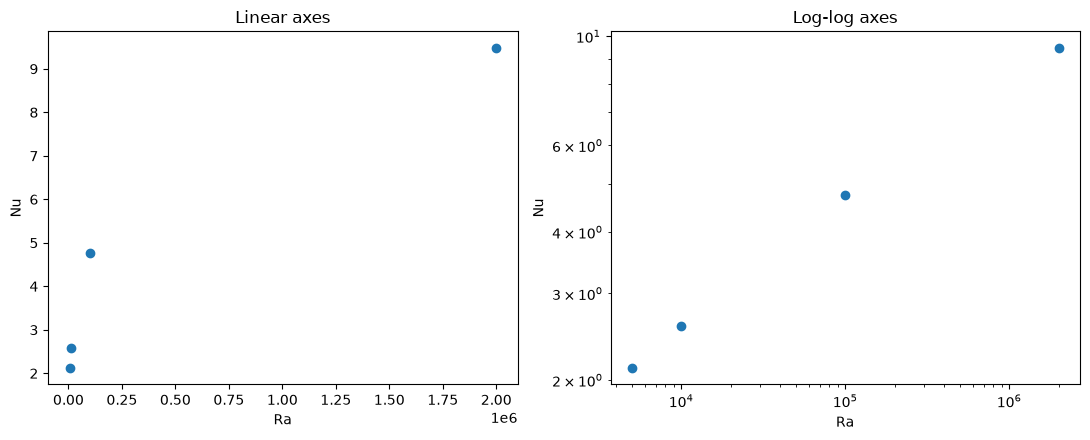

In [66]:
Ra_arr, Nu_arr, dNu_arr = compute_nusselt(data, tstart)

print(f"{'Ra':>8} {'Nu':>8} {'dNu':>8}")
for Ra, nu, dnu in zip(Ra_arr, Nu_arr, dNu_arr):
    print(f"{Ra:8.0e} {nu:8.3f} {dnu:8.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for ax in (ax1, ax2):
    ax.errorbar(Ra_arr, Nu_arr, yerr=dNu_arr, fmt='o', capsize=3)
    ax.set_xlabel('Ra')
    ax.set_ylabel('Nu')
ax1.set_title('Linear axes')
ax2.set_xscale('log'); ax2.set_yscale('log')
ax2.set_title('Log-log axes')
fig.tight_layout()
fig.savefig('nu_vs_ra.pdf')

In [ ]:
#i will now add some more data points to add to these 2 plots. i will start off just within the current range,
#as i know the simulation works at the current resolution. 
#For higher Ra, eg >2e6, i will need to see if the resolution needs to be increased (following advice from typenotes handout)

  Ra = 2e+04:  t = 22.8 / 100,  dt = 0.0399
  Ra = 2e+04:  t = 27.5 / 100,  dt = 0.0223
  Ra = 2e+04:  t = 32.7 / 100,  dt = 0.0254
  Ra = 2e+04:  t = 36.6 / 100,  dt = 0.0191
  Ra = 2e+04:  t = 41.0 / 100,  dt = 0.0237
  Ra = 2e+04:  t = 45.6 / 100,  dt = 0.0225
  Ra = 2e+04:  t = 50.1 / 100,  dt = 0.0225
  Ra = 2e+04:  t = 54.6 / 100,  dt = 0.0225
  Ra = 2e+04:  t = 59.1 / 100,  dt = 0.0225
  Ra = 2e+04:  t = 63.6 / 100,  dt = 0.0225
  Ra = 2e+04:  t = 68.1 / 100,  dt = 0.0225
  Ra = 2e+04:  t = 72.5 / 100,  dt = 0.0225
  Ra = 2e+04:  t = 77.2 / 100,  dt = 0.0236
  Ra = 2e+04:  t = 82.0 / 100,  dt = 0.0236
  Ra = 2e+04:  t = 86.7 / 100,  dt = 0.0236
  Ra = 2e+04:  t = 91.4 / 100,  dt = 0.0236
  Ra = 2e+04:  t = 96.1 / 100,  dt = 0.0236
Ra = 2e+04 finished in 205 s -> snapshots_Ra2e04
Ra = 2e+04: done in 3.6 min, 401 snapshots, t up to 100.0


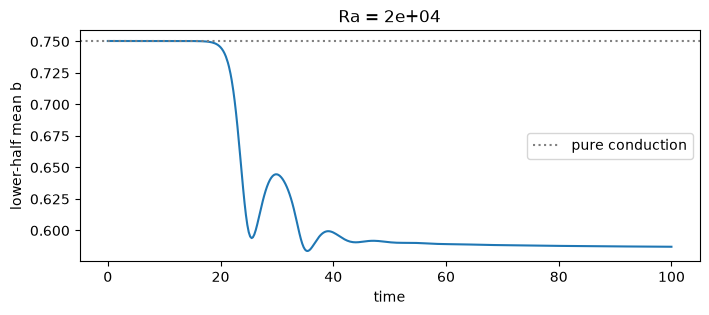

  Ra = 2e+05:  t = 15.6 / 75,  dt = 0.0135
  Ra = 2e+05:  t = 18.0 / 75,  dt = 0.0112
  Ra = 2e+05:  t = 20.3 / 75,  dt = 0.0136
  Ra = 2e+05:  t = 23.5 / 75,  dt = 0.0154
  Ra = 2e+05:  t = 26.7 / 75,  dt = 0.0163
  Ra = 2e+05:  t = 29.7 / 75,  dt = 0.0154
  Ra = 2e+05:  t = 32.5 / 75,  dt = 0.0136
  Ra = 2e+05:  t = 35.3 / 75,  dt = 0.0152
  Ra = 2e+05:  t = 38.4 / 75,  dt = 0.0152
  Ra = 2e+05:  t = 41.4 / 75,  dt = 0.0152
  Ra = 2e+05:  t = 44.5 / 75,  dt = 0.0160
  Ra = 2e+05:  t = 47.6 / 75,  dt = 0.0151
  Ra = 2e+05:  t = 50.6 / 75,  dt = 0.0151
  Ra = 2e+05:  t = 53.6 / 75,  dt = 0.0151
  Ra = 2e+05:  t = 56.6 / 75,  dt = 0.0151
  Ra = 2e+05:  t = 59.7 / 75,  dt = 0.0151
  Ra = 2e+05:  t = 62.7 / 75,  dt = 0.0159
  Ra = 2e+05:  t = 65.9 / 75,  dt = 0.0159
  Ra = 2e+05:  t = 69.1 / 75,  dt = 0.0159
  Ra = 2e+05:  t = 72.3 / 75,  dt = 0.0159
Ra = 2e+05 finished in 228 s -> snapshots_Ra2e05
Ra = 2e+05: done in 3.9 min, 301 snapshots, t up to 75.0


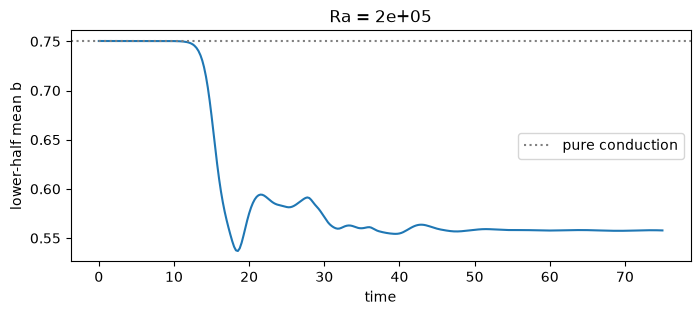

  Ra = 1e+06:  t = 13.9 / 75,  dt = 0.0100
  Ra = 1e+06:  t = 15.6 / 75,  dt = 0.0088
  Ra = 1e+06:  t = 17.4 / 75,  dt = 0.0106
  Ra = 1e+06:  t = 19.8 / 75,  dt = 0.0126
  Ra = 1e+06:  t = 22.0 / 75,  dt = 0.0113
  Ra = 1e+06:  t = 24.5 / 75,  dt = 0.0140
  Ra = 1e+06:  t = 27.2 / 75,  dt = 0.0124
  Ra = 1e+06:  t = 29.6 / 75,  dt = 0.0123
  Ra = 1e+06:  t = 32.2 / 75,  dt = 0.0129
  Ra = 1e+06:  t = 34.8 / 75,  dt = 0.0120
  Ra = 1e+06:  t = 37.0 / 75,  dt = 0.0107
  Ra = 1e+06:  t = 39.2 / 75,  dt = 0.0119
  Ra = 1e+06:  t = 41.7 / 75,  dt = 0.0112
  Ra = 1e+06:  t = 43.9 / 75,  dt = 0.0125
  Ra = 1e+06:  t = 46.3 / 75,  dt = 0.0112
  Ra = 1e+06:  t = 48.6 / 75,  dt = 0.0111
  Ra = 1e+06:  t = 51.0 / 75,  dt = 0.0131
  Ra = 1e+06:  t = 53.6 / 75,  dt = 0.0123
  Ra = 1e+06:  t = 56.1 / 75,  dt = 0.0123
  Ra = 1e+06:  t = 58.7 / 75,  dt = 0.0136
  Ra = 1e+06:  t = 61.3 / 75,  dt = 0.0123
  Ra = 1e+06:  t = 63.8 / 75,  dt = 0.0130
  Ra = 1e+06:  t = 66.3 / 75,  dt = 0.0123
  Ra = 1e+0

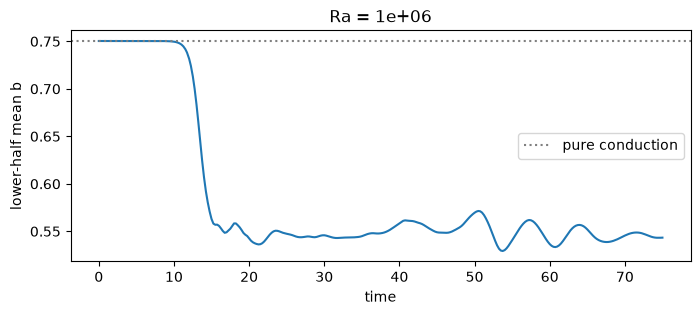

In [67]:
runs = {2e4: 100, 2e5: 75, 1e6: 75}      # Ra: stop_sim_time

for Ra, t_stop in runs.items():
    t0 = time.time()
    folders[Ra] = run_rayleigh_benard(Ra, stop_sim_time=t_stop)     # default Nx=256, Nz=64
    t, x, z, b = load_task(folders[Ra])
    data[Ra] = dict(t=t, z=z, bxm=b.mean(axis=1))                   # x-average each snapshot
    print(f"Ra = {Ra:.0e}: done in {(time.time() - t0)/60:.1f} min, "
          f"{len(t)} snapshots, t up to {t[-1]:.1f}")

    # settling diagnostic: mean b of the lower half vs time (conduction value = 0.75)
    lower = z < Lz / 2
    w = np.gradient(z)[lower]
    b_lower = (data[Ra]['bxm'][:, lower] * w).sum(axis=1) / w.sum()
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(t, b_lower)
    ax.axhline(0.75, color='grey', ls=':', label='pure conduction')
    ax.set_xlabel('time'); ax.set_ylabel('lower-half mean b')
    ax.set_title(f'Ra = {Ra:.0e}')
    ax.legend()
    plt.show()

In [68]:
tstart.update({2e4: 45, 2e5: 45, 1e6: 20})    # fill in from the settling plots

In [ ]:
#now replot the Nusselt number graphs including the new Ras (2e4, 2e5, 1e6).

      Ra       Nu      dNu
   5e+03    2.112    0.000
   1e+04    2.575    0.001
   2e+04    3.204    0.002
   1e+05    4.760    0.008
   2e+05    5.947    0.005
   1e+06    8.260    0.015
   2e+06    9.479    0.014


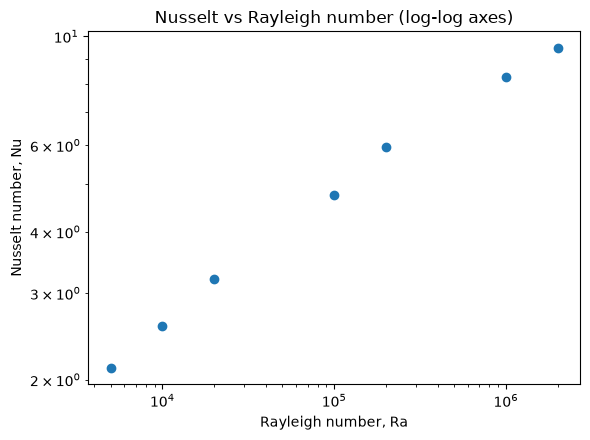

In [70]:
Ra_arr, Nu_arr, dNu_arr = compute_nusselt(data, tstart)

print(f"{'Ra':>8} {'Nu':>8} {'dNu':>8}")
for Ra, nu, dnu in zip(Ra_arr, Nu_arr, dNu_arr):
    print(f"{Ra:8.0e} {nu:8.3f} {dnu:8.3f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.errorbar(Ra_arr, Nu_arr, yerr=dNu_arr, fmt='o', capsize=3)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Rayleigh number, Ra')
ax.set_ylabel('Nusselt number, Nu')
ax.set_title('Nusselt vs Rayleigh number (log-log axes)')
fig.tight_layout()
fig.savefig('nu_vs_ra.pdf')

In order to decrease my uncertainity in the scaling relationship, I could keep adding more points to the above graph
However, i won't add any more below Ra=2e6 for now, due to the space each run takes up on my computer.
I will now focus on running simulations at higher Ra. 
Due to the steeper temp gradient near the boundaries (as the interior is nearly completely isothermal),
I may need to increase the resolution beyond the values set in Dedalus' own example script (which were Nx=256, Nz=64).
Rather than choosing an abitrary higher resolution, I will start with Nx=256, Nz=64, and then run 

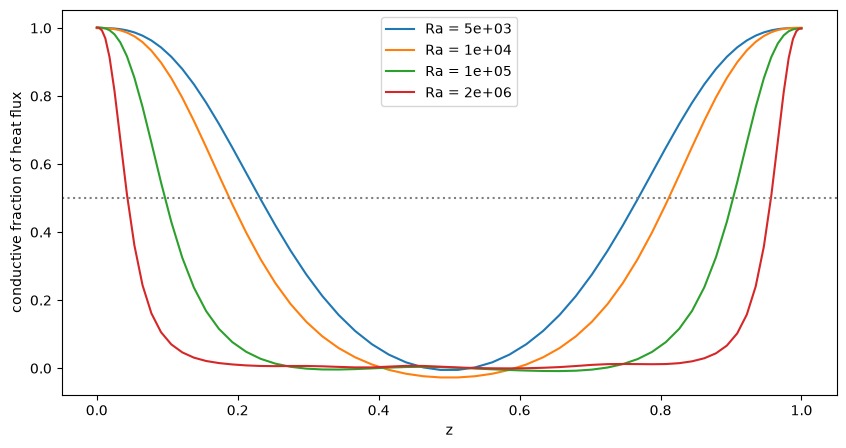

In [63]:
fig, ax = plt.subplots(figsize=(10, 5))
for Ra, d in sorted(data.items()):
    keep = d['t'] >= tstart[Ra]
    b_mean = d['bxm'][keep].mean(axis=0)
    cond_frac = -np.gradient(b_mean, d['z']) / Nu[Ra]    # local gradient / total flux
    ax.plot(d['z'], cond_frac, label=f'Ra = {Ra:.0e}')
ax.axhline(0.5, color='grey', ls=':')
ax.set_xlabel('z'); ax.set_ylabel('conductive fraction of heat flux')
ax.legend()